<a href="https://colab.research.google.com/github/dheerisfound-png/hcltech-project/blob/main/retail_sales_analysis_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Retail Sales Performance Analysis (Google Colab)
Premium clothing & garments store: Tasks 1-15.

**How to run:** `Runtime > Run all`. When the upload prompt appears in step 0, choose `retail_sales_random_cleaned.csv`.
(Or upload the file to the Colab file panel on the left first; the notebook will find it.)

## 0. Setup and load the data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.options.display.float_format = "{:,.2f}".format

FILE = "retail_sales_random_cleaned.csv"

try:                                    # inside Google Colab
    from google.colab import files
    IN_COLAB = True
except ImportError:                     # running locally / Jupyter
    IN_COLAB = False

if IN_COLAB and not Path(FILE).exists():
    print(f"Please choose {FILE} in the upload dialog...")
    uploaded = files.upload()
    FILE = next(iter(uploaded))         # use whatever name Colab saved it under
print("Using file:", FILE)

OUT = Path("analysis_output")
OUT.mkdir(exist_ok=True)

Please choose retail_sales_random_cleaned.csv in the upload dialog...


Saving retail_sales_random_cleaned (1).csv to retail_sales_random_cleaned (1).csv
Using file: retail_sales_random_cleaned (1).csv


## 1. Load the CSV and inspect dimensions, columns and data types

In [ ]:
df = pd.read_csv(FILE)
print("Rows x columns:", df.shape)
display(df.head())
print(df.dtypes)

# Keep the original business columns; derived columns are rebuilt in the steps below
BASE_COLS = ["Order_ID", "Order_Date", "City", "Product", "Category", "Quantity",
             "Unit_Price", "Customer_ID", "Payment_Mode", "Revenue"]
df = df[BASE_COLS]

Rows x columns: (1000, 15)


,Order_ID,Order_Date,City,Product,Category,Quantity,Unit_Price,Customer_ID,Payment_Mode,Revenue,Month,Year_Month,Month_Name,Weekday,Calc_Revenue
0,ORD00000,2025-01-01,Chennai,Leather Jacket,Outerwear,2,18999,C0074,Card,37998,1,2025-01,January,Wednesday,37998
1,ORD00001,2025-01-02,Delhi,Dress Shirt,Formal Wear,1,2499,C0079,UPI,2499,1,2025-01,January,Thursday,2499
2,ORD00002,2025-01-02,Mumbai,Sherwani,Ethnic Wear,1,44999,C0072,UPI,44999,1,2025-01,January,Thursday,44999
3,ORD00003,2025-01-03,Delhi,Denim Jeans,Casual Wear,1,2999,C0250,UPI,2999,1,2025-01,January,Friday,2999
4,ORD00004,2025-01-04,Bengaluru,Cashmere Sweater,Casual Wear,1,5999,C0100,Card,5999,1,2025-01,January,Saturday,5999


Order_ID        object
Order_Date      object
City            object
Product         object
Category        object
Quantity         int64
Unit_Price       int64
Customer_ID     object
Payment_Mode    object
Revenue          int64
Month            int64
Year_Month      object
Month_Name      object
Weekday         object
Calc_Revenue     int64
dtype: object


## 2. Missing values and duplicate orders

In [ ]:
print("Missing values per column:")
print(df.isna().sum())
print("\nExact duplicate rows:", df.duplicated().sum())
print("Repeated Order_IDs  :", df.Order_ID.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(df))

Missing values per column:
Order_ID        0
Order_Date      0
City            0
Product         0
Category        0
Quantity        0
Unit_Price      0
Customer_ID     0
Payment_Mode    0
Revenue         0
dtype: int64

Exact duplicate rows: 0
Repeated Order_IDs  : 0
Rows after removing duplicates: 1000


## 3. Clean missing City values
Strategy: fill from the customer's other orders when they all share one city; otherwise label `Unknown`.
Filling with the most common city would invent sales for the biggest city. (This file has no gaps, so this is a safeguard.)

In [ ]:
cust_city = (df.dropna(subset=["City"]).groupby("Customer_ID").City
               .agg(lambda c: c.iloc[0] if c.nunique() == 1 else np.nan))
df["City"] = df["City"].fillna(df["Customer_ID"].map(cust_city)).fillna("Unknown")
print("Missing City after cleaning:", df.City.isna().sum(), "| 'Unknown' rows:", (df.City == "Unknown").sum())

Missing City after cleaning: 0 | 'Unknown' rows: 0


## 4. Convert Order_Date to datetime; extract month and weekday

In [ ]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
df["Month"] = df["Order_Date"].dt.month
df["Year_Month"] = df["Order_Date"].dt.to_period("M").astype(str)
df["Month_Name"] = df["Order_Date"].dt.month_name()
df["Weekday"] = df["Order_Date"].dt.day_name()
print(df.Order_Date.dtype, "|", df.Order_Date.min().date(), "to", df.Order_Date.max().date())
display(df[["Order_Date", "Month", "Month_Name", "Weekday"]].head())

datetime64[ns] | 2025-01-01 to 2026-05-15


,Order_Date,Month,Month_Name,Weekday
0,2025-01-01,1,January,Wednesday
1,2025-01-02,1,January,Thursday
2,2025-01-02,1,January,Thursday
3,2025-01-03,1,January,Friday
4,2025-01-04,1,January,Saturday


## 5. Row-wise revenue and verification of the Revenue column

In [ ]:
df["Calc_Revenue"] = df["Quantity"] * df["Unit_Price"]
mismatch = int((df.Calc_Revenue != df.Revenue).sum())
print("Rows where Revenue != Quantity x Unit_Price:", mismatch)
print("Revenue column is reliable" if mismatch == 0 else "Check the mismatching rows!")

Rows where Revenue != Quantity x Unit_Price: 0
Revenue column is reliable


## 6. Total revenue, total quantity and average order value

In [ ]:
total_rev = df.Revenue.sum()
total_qty = df.Quantity.sum()
n_orders = df.Order_ID.nunique()
aov = total_rev / n_orders

kpi = pd.DataFrame({
    "Metric": ["Total revenue", "Total quantity", "Orders", "Average order value",
               "Unique customers", "Date range"],
    "Value": [f"{total_rev:,.0f}", f"{total_qty:,}", f"{n_orders:,}", f"{aov:,.2f}",
              f"{df.Customer_ID.nunique():,}",
              f"{df.Order_Date.min().date()} to {df.Order_Date.max().date()}"]})
display(kpi)

,Metric,Value
0,Total revenue,"21,112,262"
1,Total quantity,"1,738"
2,Orders,"1,000"
3,Average order value,"21,112.26"
4,Unique customers,295
5,Date range,2025-01-01 to 2026-05-15


## 7. Top 10 products by revenue

,Product,Category,Revenue,Quantity,Orders,Revenue_Share_%
0,Leather Jacket,Outerwear,4304859,141,81,20.40
1,Wool Coat,Outerwear,3430843,157,93,16.30
2,Silk Saree,Ethnic Wear,2570870,130,73,12.20
3,Sherwani,Ethnic Wear,2094934,66,40,9.90
4,Tailored Blazer,Formal Wear,1663872,128,68,7.90
5,Designer Dress,Casual Wear,1475897,103,60,7.00
6,Kurta Set,Ethnic Wear,1334838,162,88,6.30
7,Cashmere Sweater,Casual Wear,1129883,117,76,5.40
8,Denim Jeans,Casual Wear,1107266,234,140,5.20
9,Dress Shirt,Formal Wear,884271,229,126,4.20


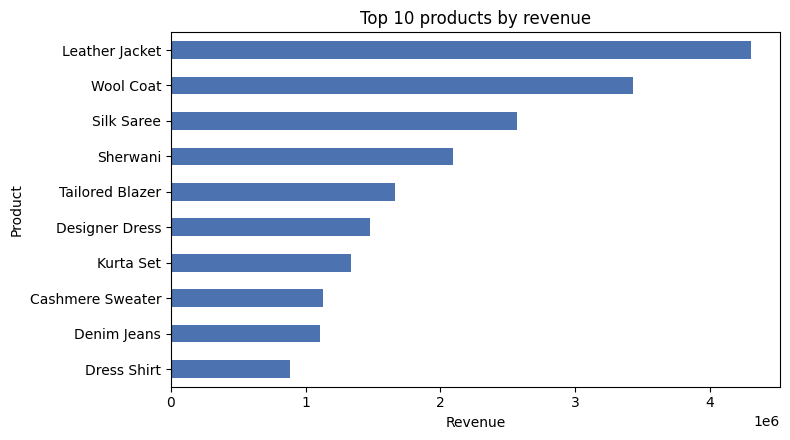

In [ ]:
prod = (df.groupby(["Product", "Category"])
          .agg(Revenue=("Revenue", "sum"), Quantity=("Quantity", "sum"), Orders=("Order_ID", "size"))
          .sort_values("Revenue", ascending=False).reset_index())
prod["Revenue_Share_%"] = (prod.Revenue / total_rev * 100).round(1)
display(prod.head(10))

ax = prod.head(10).iloc[::-1].plot.barh(x="Product", y="Revenue", legend=False, figsize=(8, 4.5), color="#4C72B0")
ax.set_title("Top 10 products by revenue"); ax.set_xlabel("Revenue"); plt.tight_layout(); plt.show()

## 8. Rank cities by revenue

In [ ]:
city = (df.groupby("City").agg(Revenue=("Revenue", "sum"), Orders=("Order_ID", "size"),
                               Customers=("Customer_ID", "nunique"))
          .sort_values("Revenue", ascending=False))
city["AOV"] = (city.Revenue / city.Orders).round(0)
city["Revenue_Share_%"] = (city.Revenue / total_rev * 100).round(1)
city.insert(0, "Rank", range(1, len(city) + 1))
city = city.reset_index()
display(city)

,City,Rank,Revenue,Orders,Customers,AOV,Revenue_Share_%
0,Bengaluru,1,4977124,219,60,"22,727.00",23.60
1,Delhi,2,4648117,225,67,"20,658.00",22.00
2,Mumbai,3,4230146,201,65,"21,046.00",20.00
3,Hyderabad,4,2689778,124,35,"21,692.00",12.70
4,Chennai,5,2392302,110,33,"21,748.00",11.30
5,Pune,6,2174795,121,35,"17,974.00",10.30


## 9. Monthly revenue and best month

,Year_Month,Revenue,Orders
0,2025-01,1266896,63
1,2025-02,1262394,64
2,2025-03,990428,45
3,2025-04,612924,46
4,2025-05,1049909,52
5,2025-06,1072899,58
6,2025-07,1044405,56
7,2025-08,882423,41
8,2025-09,1078906,49
9,2025-10,1118388,69


Best month: 2025-12  (revenue 2,495,824)
Note: the last month is partial if the data ends mid-month.


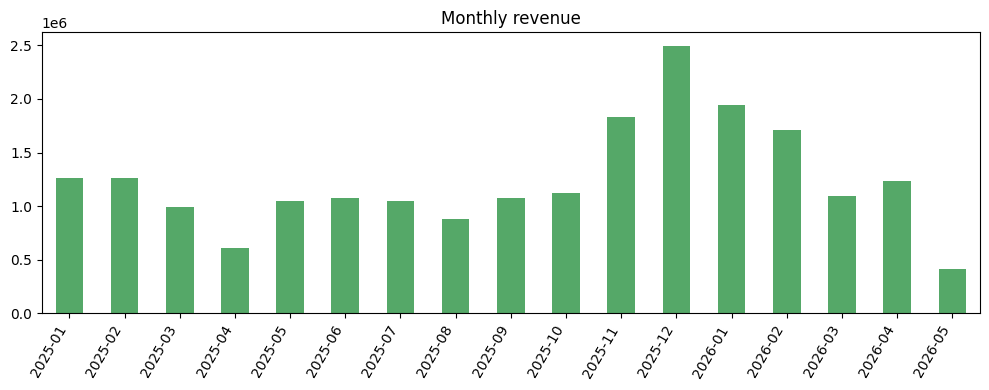

,Weekday,Revenue,Orders
0,Monday,3190720,154
1,Tuesday,2782279,126
2,Wednesday,2580279,127
3,Thursday,2873278,133
4,Friday,2575315,107
5,Saturday,3401204,171
6,Sunday,3709187,182


In [ ]:
monthly = (df.groupby("Year_Month").agg(Revenue=("Revenue", "sum"), Orders=("Order_ID", "size"))
             .reset_index())
best = monthly.loc[monthly.Revenue.idxmax()]
display(monthly)
print(f"Best month: {best.Year_Month}  (revenue {best.Revenue:,.0f})")
print("Note: the last month is partial if the data ends mid-month.")

ax = monthly.plot(x="Year_Month", y="Revenue", kind="bar", legend=False, figsize=(10, 4), color="#55A868")
ax.set_title("Monthly revenue"); ax.set_xlabel(""); plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday = (df.groupby("Weekday").agg(Revenue=("Revenue", "sum"), Orders=("Order_ID", "size"))
             .reindex(order).reset_index())
display(weekday)

## 10. Top 10 customers by total spending

In [ ]:
cust = (df.groupby("Customer_ID").agg(Total_Spend=("Revenue", "sum"), Orders=("Order_ID", "size"))
          .sort_values("Total_Spend", ascending=False))
cust["Share_%"] = (cust.Total_Spend / total_rev * 100).round(2)
display(cust.head(10).reset_index())

top20_n = int(len(cust) * 0.2)
print(f"Top 10 customers = {cust.head(10).Total_Spend.sum() / total_rev * 100:.1f}% of revenue")
print(f"Top 20% of customers ({top20_n}) = {cust.head(top20_n).Total_Spend.sum() / total_rev * 100:.1f}% of revenue")
print("Repeat customers:", int((cust.Orders > 1).sum()), "of", len(cust))

,Customer_ID,Total_Spend,Orders,Share_%
0,C0198,553461,14,2.62
1,C0153,542967,21,2.57
2,C0021,380981,8,1.80
3,C0089,362476,13,1.72
4,C0047,339976,12,1.61
5,C0187,317971,19,1.51
6,C0226,309972,19,1.47
7,C0044,283980,11,1.35
8,C0302,268975,12,1.27
9,C0130,245988,6,1.17


Top 10 customers = 17.1% of revenue
Top 20% of customers (59) = 51.0% of revenue
Repeat customers: 242 of 295


## 11. Payment methods: orders and revenue

In [ ]:
pay = (df.groupby("Payment_Mode").agg(Orders=("Order_ID", "size"), Revenue=("Revenue", "sum"))
         .sort_values("Revenue", ascending=False))
pay["AOV"] = (pay.Revenue / pay.Orders).round(0)
pay["Revenue_Share_%"] = (pay.Revenue / total_rev * 100).round(1)
pay = pay.reset_index()
display(pay)

,Payment_Mode,Orders,Revenue,AOV,Revenue_Share_%
0,Card,390,8408810,"21,561.00",39.80
1,UPI,316,6614954,"20,933.00",31.30
2,NetBanking,180,3514198,"19,523.00",16.60
3,Cash,114,2574300,"22,582.00",12.20


## 12. Unusually large orders (IQR method)

In [ ]:
q1, q3 = np.percentile(df.Revenue, [25, 75])
iqr = q3 - q1
low_fence, high_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df.Revenue < low_fence) | (df.Revenue > high_fence)].sort_values("Revenue", ascending=False)

print(f"Q1 = {q1:,.0f} | Q3 = {q3:,.0f} | IQR = {iqr:,.0f}")
print(f"Fences: lower = {low_fence:,.0f}, upper = {high_fence:,.0f}")
print(f"Outliers: {len(outliers)} orders ({len(outliers)/len(df)*100:.1f}%) = "
      f"{outliers.Revenue.sum()/total_rev*100:.1f}% of revenue")
print("By product:", outliers.Product.value_counts().to_dict())
display(outliers.head(10))

Q1 = 5,999 | Q3 = 27,997 | IQR = 21,998
Fences: lower = -26,998, upper = 60,993
Outliers: 49 orders (4.9%) = 22.5% of revenue
By product: {'Leather Jacket': 17, 'Wool Coat': 9, 'Silk Saree': 9, 'Sherwani': 8, 'Tailored Blazer': 3, 'Designer Dress': 1, 'Cashmere Sweater': 1, 'Kurta Set': 1}


,Order_ID,Order_Date,City,Product,Category,Quantity,Unit_Price,Customer_ID,Payment_Mode,Revenue,Month,Year_Month,Month_Name,Weekday,Calc_Revenue
164,ORD00164,2025-03-23,Mumbai,Sherwani,Ethnic Wear,3,64999,C0080,NetBanking,194997,3,2025-03,March,Sunday,194997
561,ORD00561,2025-11-06,Bengaluru,Sherwani,Ethnic Wear,3,64999,C0227,Card,194997,11,2025-11,November,Thursday,194997
460,ORD00460,2025-09-19,Delhi,Leather Jacket,Outerwear,3,54999,C0198,Cash,164997,9,2025-09,September,Friday,164997
876,ORD00876,2026-03-09,Bengaluru,Leather Jacket,Outerwear,4,38999,C0089,UPI,155996,3,2026-03,March,Monday,155996
392,ORD00392,2025-08-03,Bengaluru,Leather Jacket,Outerwear,4,38999,C0021,UPI,155996,8,2025-08,August,Sunday,155996
919,ORD00919,2026-04-04,Hyderabad,Sherwani,Ethnic Wear,3,44999,C0113,Card,134997,4,2026-04,April,Saturday,134997
793,ORD00793,2026-01-29,Mumbai,Wool Coat,Outerwear,4,29999,C0068,UPI,119996,1,2026-01,January,Thursday,119996
827,ORD00827,2026-02-14,Delhi,Leather Jacket,Outerwear,3,38999,C0220,Card,116997,2,2026-02,February,Saturday,116997
16,ORD00016,2025-01-10,Bengaluru,Leather Jacket,Outerwear,4,27999,C0047,Cash,111996,1,2025-01,January,Friday,111996
818,ORD00818,2026-02-09,Bengaluru,Silk Saree,Ethnic Wear,4,27999,C0130,Card,111996,2,2026-02,February,Monday,111996


## 13. Product-category summary (groupby)

,Category,Orders,Quantity,Revenue,Avg_Order_Value,Avg_Unit_Price,Revenue_Share_%
0,Outerwear,174,298,7735702,"44,458.10","26,476.00",36.60
1,Ethnic Wear,201,358,6000642,"29,853.90","16,929.30",28.40
2,Casual Wear,276,454,3713046,"13,453.10","8,229.10",17.60
3,Formal Wear,291,522,3394978,"11,666.60","6,420.00",16.10
4,Accessories,58,106,267894,"4,618.90","2,499.00",1.30


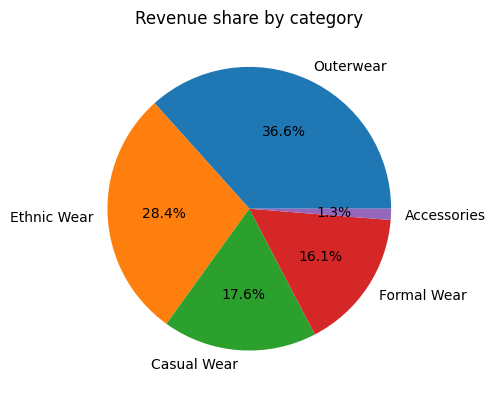

In [ ]:
cat = (df.groupby("Category").agg(Orders=("Order_ID", "size"), Quantity=("Quantity", "sum"),
                                  Revenue=("Revenue", "sum"), Avg_Order_Value=("Revenue", "mean"),
                                  Avg_Unit_Price=("Unit_Price", "mean"))
         .round(1).sort_values("Revenue", ascending=False))
cat["Revenue_Share_%"] = (cat.Revenue / total_rev * 100).round(1)
cat = cat.reset_index()
display(cat)

ax = cat.set_index("Category")["Revenue"].plot.pie(autopct="%1.1f%%", figsize=(5, 5), ylabel="")
ax.set_title("Revenue share by category"); plt.tight_layout(); plt.show()

## 14. NumPy: mean, median and standard deviation of order revenue

In [ ]:
rev = df.Revenue.to_numpy()
np_stats = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Std dev (sample, ddof=1)", "Std dev (population)"],
    "Value": [np.mean(rev), np.median(rev), np.std(rev, ddof=1), np.std(rev)]}).round(2)
display(np_stats)
print(f"Mean / median = {np.mean(rev) / np.median(rev):.2f}: the mean sits above the median, so order values are right-skewed.")

,Statistic,Value
0,Mean,"21,112.26"
1,Median,"12,998.50"
2,"Std dev (sample, ddof=1)","23,687.90"
3,Std dev (population),"23,676.05"


Mean / median = 1.62: the mean sits above the median, so order values are right-skewed.


## Extra: price bands

In [ ]:
bands = pd.cut(df.Unit_Price, [0, 5000, 15000, np.inf],
               labels=["Entry (<5K)", "Core (5K-15K)", "Luxury (>15K)"])
price_bands = (df.groupby(bands, observed=True)
                 .agg(Orders=("Order_ID", "size"), Quantity=("Quantity", "sum"), Revenue=("Revenue", "sum")))
price_bands["Revenue_Share_%"] = (price_bands.Revenue / total_rev * 100).round(1)
price_bands["Order_Share_%"] = (price_bands.Orders / len(df) * 100).round(1)
price_bands = price_bands.rename_axis("Price_Band").reset_index()
display(price_bands)

,Price_Band,Orders,Quantity,Revenue,Revenue_Share_%,Order_Share_%
0,Entry (<5K),356,622,2116378,10.00,35.60
1,Core (5K-15K),358,630,5884370,27.90,35.80
2,Luxury (>15K),286,486,13111514,62.10,28.60


## 15. Business recommendations
The cell below prints the headline evidence from your data; use it to write or update your five recommendations.

In [ ]:
top_cat = cat.iloc[0]
top_two_share = cat.head(2)["Revenue_Share_%"].sum()
winter = df[df.Month.isin([11, 12, 1, 2])].Revenue.sum() / total_rev * 100

evidence = [
    f"1. Product/category focus: {cat.iloc[0].Category} and {cat.iloc[1].Category} bring in {top_two_share:.1f}% of revenue; "
    f"top product is {prod.iloc[0].Product} ({prod.iloc[0]['Revenue_Share_%']}%).",
    f"2. Seasonality: best month {best.Year_Month}; all Nov-Feb calendar months (both years) carry {winter:.1f}% of revenue.",
    f"3. Basket size: lowest-AOV category is {cat.sort_values('Avg_Order_Value').iloc[0].Category} "
    f"(AOV {cat.sort_values('Avg_Order_Value').iloc[0].Avg_Order_Value:,.0f}); bundle / cross-sell candidates.",
    f"4. Customers & large orders: top 20% of customers = {cust.head(top20_n).Total_Spend.sum() / total_rev * 100:.1f}% of revenue; "
    f"{len(outliers)} outlier orders = {outliers.Revenue.sum()/total_rev*100:.1f}% of revenue.",
    f"5. Regions & payments: {city.iloc[0].City} leads ({city.iloc[0]['Revenue_Share_%']}%), "
    f"{city.iloc[-1].City} is last ({city.iloc[-1]['Revenue_Share_%']}%); "
    f"top payment method is {pay.iloc[0].Payment_Mode} ({pay.iloc[0]['Revenue_Share_%']}% of revenue).",
]
print("\n".join(evidence))

1. Product/category focus: Outerwear and Ethnic Wear bring in 65.0% of revenue; top product is Leather Jacket (20.4%).
2. Seasonality: best month 2025-12; all Nov-Feb calendar months (both years) carry 49.8% of revenue.
3. Basket size: lowest-AOV category is Accessories (AOV 4,619); bundle / cross-sell candidates.
4. Customers & large orders: top 20% of customers = 51.0% of revenue; 49 outlier orders = 22.5% of revenue.
5. Regions & payments: Bengaluru leads (23.6%), Pune is last (10.3%); top payment method is Card (39.8% of revenue).


## Save and download the results

In [ ]:
df.to_csv(OUT / "retail_sales_processed.csv", index=False)

tables = {
    "Revenue Summary": kpi, "Top 10 Products": prod.head(10), "All Products": prod,
    "City Ranking": city, "Monthly Trend": monthly, "Weekday": weekday,
    "Top 10 Customers": cust.head(10).reset_index(), "Payment Modes": pay,
    "IQR Outliers": outliers, "Category Summary": cat, "NumPy Stats": np_stats,
    "Price Bands": price_bands,
}
with pd.ExcelWriter(OUT / "retail_sales_analysis_tables.xlsx") as xw:
    for name, t in tables.items():
        t.to_excel(xw, sheet_name=name, index=False)
print("Saved to:", OUT.resolve(), "->", [p.name for p in OUT.iterdir()])

if IN_COLAB:                              # trigger browser downloads
    files.download(str(OUT / "retail_sales_analysis_tables.xlsx"))
    files.download(str(OUT / "retail_sales_processed.csv"))

Saved to: /content/analysis_output -> ['retail_sales_processed.csv', 'retail_sales_analysis_tables.xlsx']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>